# 03 — Comparative Analysis: Prophet vs TimesFM

Prophet and TimesFM represent genuinely different philosophies — one leans on domain knowledge and explicit regressors, the other on pre-trained pattern recognition with zero configuration. Here I pull together both sets of results and dig into where each one actually wins, per country, by error type, and by resource cost.

**Prerequisite:** run Notebooks 01 and 02 first.

**Walkthrough:**
1. Load all results
2. Overall metrics comparison
3. Per-country performance heatmap
4. Forecast overlay visualization
5. Residual & error distribution
6. Speed & efficiency analysis
7. Strengths & weaknesses discussion
8. Export comparison report


## Loading all results


In [1]:
# Cell 1: Setup
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/ML_Prediction_Analysis'
RESULTS_DIR = f'{DRIVE_BASE}/Comparison_Results'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load results from both models
MODEL_FILES = {
    'Prophet': f'{DRIVE_BASE}/Prophet_Results/prophet_results.json',
    'TimesFM': f'{DRIVE_BASE}/TimesFM_Results/timesfm_results.json',
}

results = {}
for name, path in MODEL_FILES.items():
    if os.path.exists(path):
        with open(path, 'r') as f:
            results[name] = json.load(f)
        print(f'  Loaded: {name} ({path})')
    else:
        print(f'  WARNING: {name} results not found at {path}')

print(f'\nModels loaded: {list(results.keys())}')
assert len(results) == 2, 'Both model results are required. Run Notebooks 01 & 02 first.'

Mounted at /content/drive
  Loaded: Prophet (/content/drive/MyDrive/ML_Prediction_Analysis/Prophet_Results/prophet_results.json)
  Loaded: TimesFM (/content/drive/MyDrive/ML_Prediction_Analysis/TimesFM_Results/timesfm_results.json)

Models loaded: ['Prophet', 'TimesFM']


## Overall metrics, side by side


In [2]:
# Cell 2: Build comparison DataFrame
metrics_data = []
for model_name, res in results.items():
    m = res['metrics']['overall']
    metrics_data.append({
        'Model': model_name,
        'MAE (EUR)': m['mae'],
        'RMSE (EUR)': m['rmse'],
        'MAPE (%)': m['mape'],
        'SMAPE (%)': m['smape'],
        'Training Time (s)': res['training']['total_time_seconds'],
    })

comparison_df = pd.DataFrame(metrics_data).set_index('Model')
print('=' * 60)
print('OVERALL METRICS COMPARISON')
print('=' * 60)
print(comparison_df.round(2).to_string())

# Determine winner per metric (lower is better for all)
print('\n--- Winner per Metric ---')
for col in comparison_df.columns:
    winner = comparison_df[col].idxmin()
    diff = comparison_df[col].max() - comparison_df[col].min()
    pct = (diff / comparison_df[col].max()) * 100
    print(f'  {col}: {winner} (better by {diff:.2f}, {pct:.1f}%)')

OVERALL METRICS COMPARISON
         MAE (EUR)  RMSE (EUR)  MAPE (%)  SMAPE (%)  Training Time (s)
Model                                                                 
Prophet    1092.77     1507.09      7.40       7.30               2.14
TimesFM    1496.45     2185.28      9.11       9.29               2.64

--- Winner per Metric ---
  MAE (EUR): Prophet (better by 403.68, 27.0%)
  RMSE (EUR): Prophet (better by 678.19, 31.0%)
  MAPE (%): Prophet (better by 1.72, 18.8%)
  SMAPE (%): Prophet (better by 1.99, 21.4%)
  Training Time (s): Prophet (better by 0.50, 18.9%)


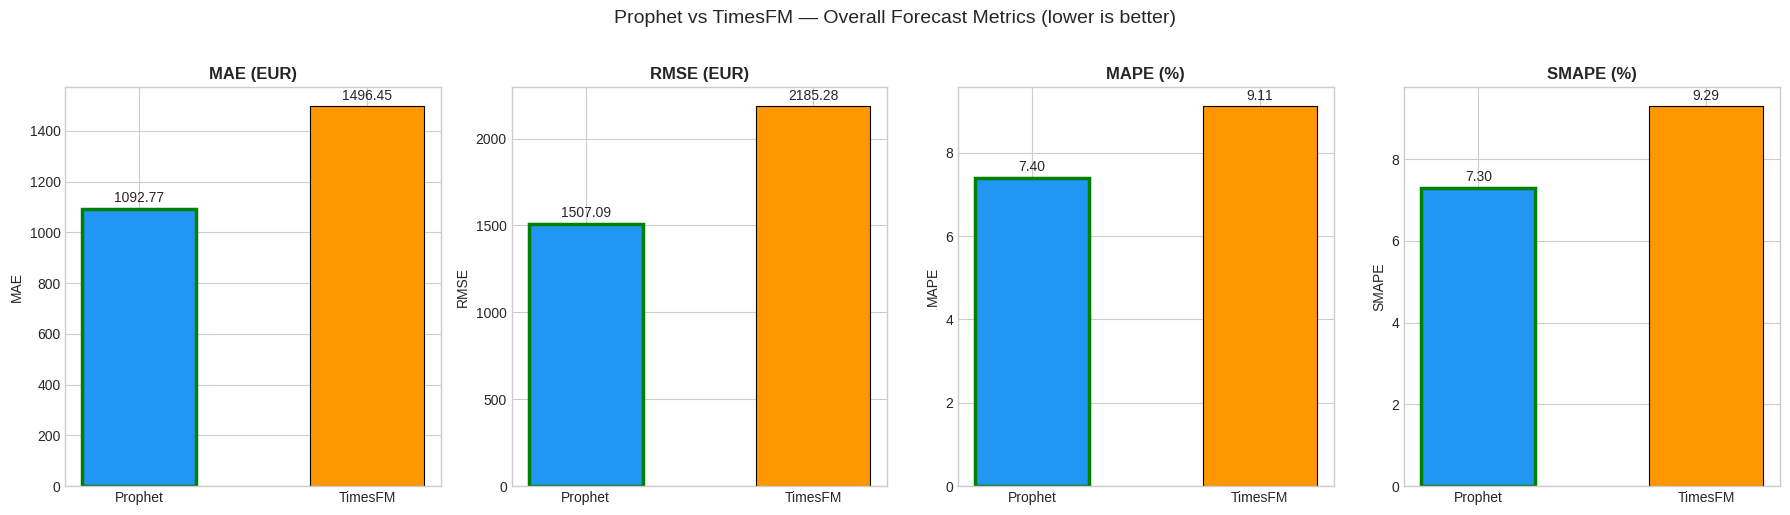

Metrics comparison plot saved.


In [3]:
# Cell 3: Metrics bar chart
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
metrics_to_plot = ['MAE (EUR)', 'RMSE (EUR)', 'MAPE (%)', 'SMAPE (%)']
colors = ['#2196F3', '#FF9800']  # Blue=Prophet, Orange=TimesFM

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]
    values = comparison_df[metric].values
    bars = ax.bar(comparison_df.index, values, color=colors, edgecolor='black',
                  linewidth=0.8, width=0.5)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel(metric.split('(')[0].strip())

    # Add value labels
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01*max(values),
                f'{val:.2f}', ha='center', va='bottom', fontsize=10)

    # Highlight winner
    winner_idx = np.argmin(values)
    bars[winner_idx].set_edgecolor('green')
    bars[winner_idx].set_linewidth(2.5)

plt.suptitle('Prophet vs TimesFM — Overall Forecast Metrics (lower is better)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_metrics_bars.png', dpi=150, bbox_inches='tight')
plt.show()
print('Metrics comparison plot saved.')

## Per-country performance heatmap

Which model actually wins in each market?


In [4]:
# Cell 4: Per-country metrics comparison
countries = results['Prophet']['dataset']['countries']

# Build per-country comparison
country_comparison = []
for country in countries:
    prophet_m = results['Prophet']['metrics']['per_country'][country]
    timesfm_m = results['TimesFM']['metrics']['per_country'][country]
    country_comparison.append({
        'Country': country,
        'Prophet MAE': prophet_m['mae'],
        'TimesFM MAE': timesfm_m['mae'],
        'Prophet MAPE': prophet_m['mape'],
        'TimesFM MAPE': timesfm_m['mape'],
        'Prophet RMSE': prophet_m['rmse'],
        'TimesFM RMSE': timesfm_m['rmse'],
        'MAE Winner': 'Prophet' if prophet_m['mae'] < timesfm_m['mae'] else 'TimesFM',
        'MAPE Winner': 'Prophet' if prophet_m['mape'] < timesfm_m['mape'] else 'TimesFM',
    })

country_df = pd.DataFrame(country_comparison)
print('=== Per-Country Comparison ===')
print(country_df.to_string(index=False))

# Count wins
print(f'\nMAE wins  — Prophet: {(country_df["MAE Winner"]=="Prophet").sum()}, '
      f'TimesFM: {(country_df["MAE Winner"]=="TimesFM").sum()}')
print(f'MAPE wins — Prophet: {(country_df["MAPE Winner"]=="Prophet").sum()}, '
      f'TimesFM: {(country_df["MAPE Winner"]=="TimesFM").sum()}')

=== Per-Country Comparison ===
Country  Prophet MAE  TimesFM MAE  Prophet MAPE  TimesFM MAPE  Prophet RMSE  TimesFM RMSE MAE Winner MAPE Winner
     BE     726.0665    1024.4096        7.3376        9.7417      922.2488     1390.0622    Prophet     Prophet
     DE    1152.1487    2433.2103        5.0651       10.4015     1525.7725     2922.1386    Prophet     Prophet
     ES    1153.6439    1251.5563        8.5192        9.3837     1502.5576     1774.3759    Prophet     Prophet
     FR    1155.0162    1865.4845        5.2312        8.1873     1796.8755     2814.0684    Prophet     Prophet
     IT    1016.6804    1491.8719        5.8980        8.7505     1298.7130     1900.4921    Prophet     Prophet
     NL    1085.9760     933.8139        8.9857        7.7163     1200.3342     1152.0419    TimesFM     TimesFM
     PT     961.2007     875.5987       12.4599       10.8765     1086.1849     1081.2454    TimesFM     TimesFM
     UK    1491.4107    2095.6290        5.6823        7.8491    

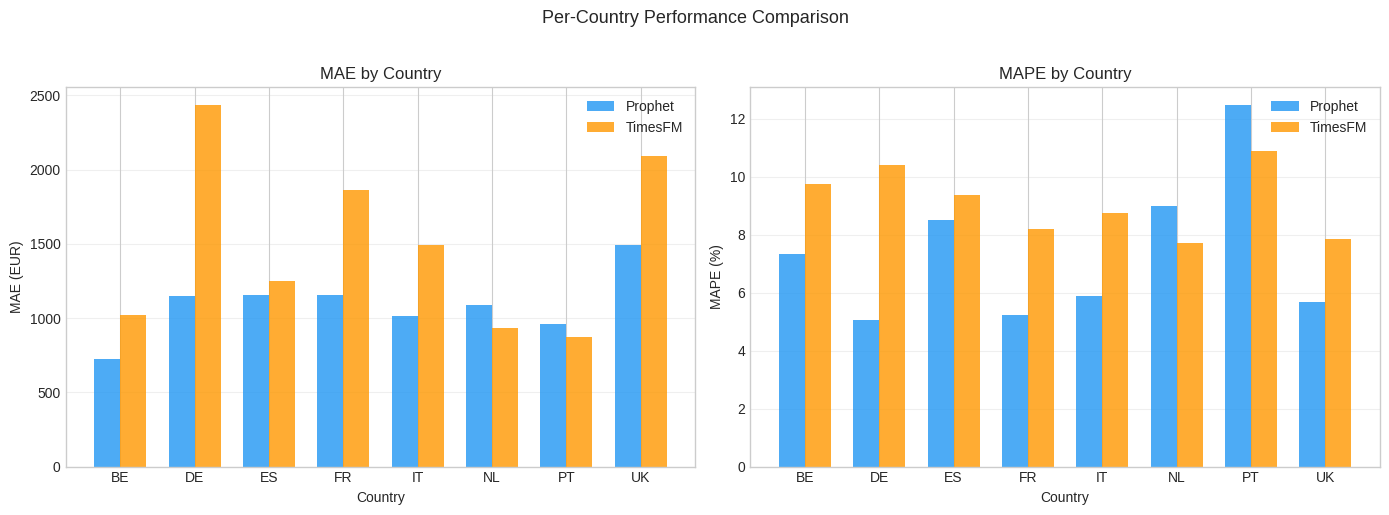

In [5]:
# Cell 5: MAPE heatmap by country and model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE comparison grouped bar
x = np.arange(len(countries))
width = 0.35

prophet_mae = [results['Prophet']['metrics']['per_country'][c]['mae'] for c in countries]
timesfm_mae = [results['TimesFM']['metrics']['per_country'][c]['mae'] for c in countries]

axes[0].bar(x - width/2, prophet_mae, width, label='Prophet', color='#2196F3', alpha=0.8)
axes[0].bar(x + width/2, timesfm_mae, width, label='TimesFM', color='#FF9800', alpha=0.8)
axes[0].set_xlabel('Country')
axes[0].set_ylabel('MAE (EUR)')
axes[0].set_title('MAE by Country')
axes[0].set_xticks(x)
axes[0].set_xticklabels(countries)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# MAPE comparison grouped bar
prophet_mape = [results['Prophet']['metrics']['per_country'][c]['mape'] for c in countries]
timesfm_mape = [results['TimesFM']['metrics']['per_country'][c]['mape'] for c in countries]

axes[1].bar(x - width/2, prophet_mape, width, label='Prophet', color='#2196F3', alpha=0.8)
axes[1].bar(x + width/2, timesfm_mape, width, label='TimesFM', color='#FF9800', alpha=0.8)
axes[1].set_xlabel('Country')
axes[1].set_ylabel('MAPE (%)')
axes[1].set_title('MAPE by Country')
axes[1].set_xticks(x)
axes[1].set_xticklabels(countries)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Per-Country Performance Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_per_country.png', dpi=150, bbox_inches='tight')
plt.show()

## Forecast overlay

Both models' predictions plotted against actuals, per country.


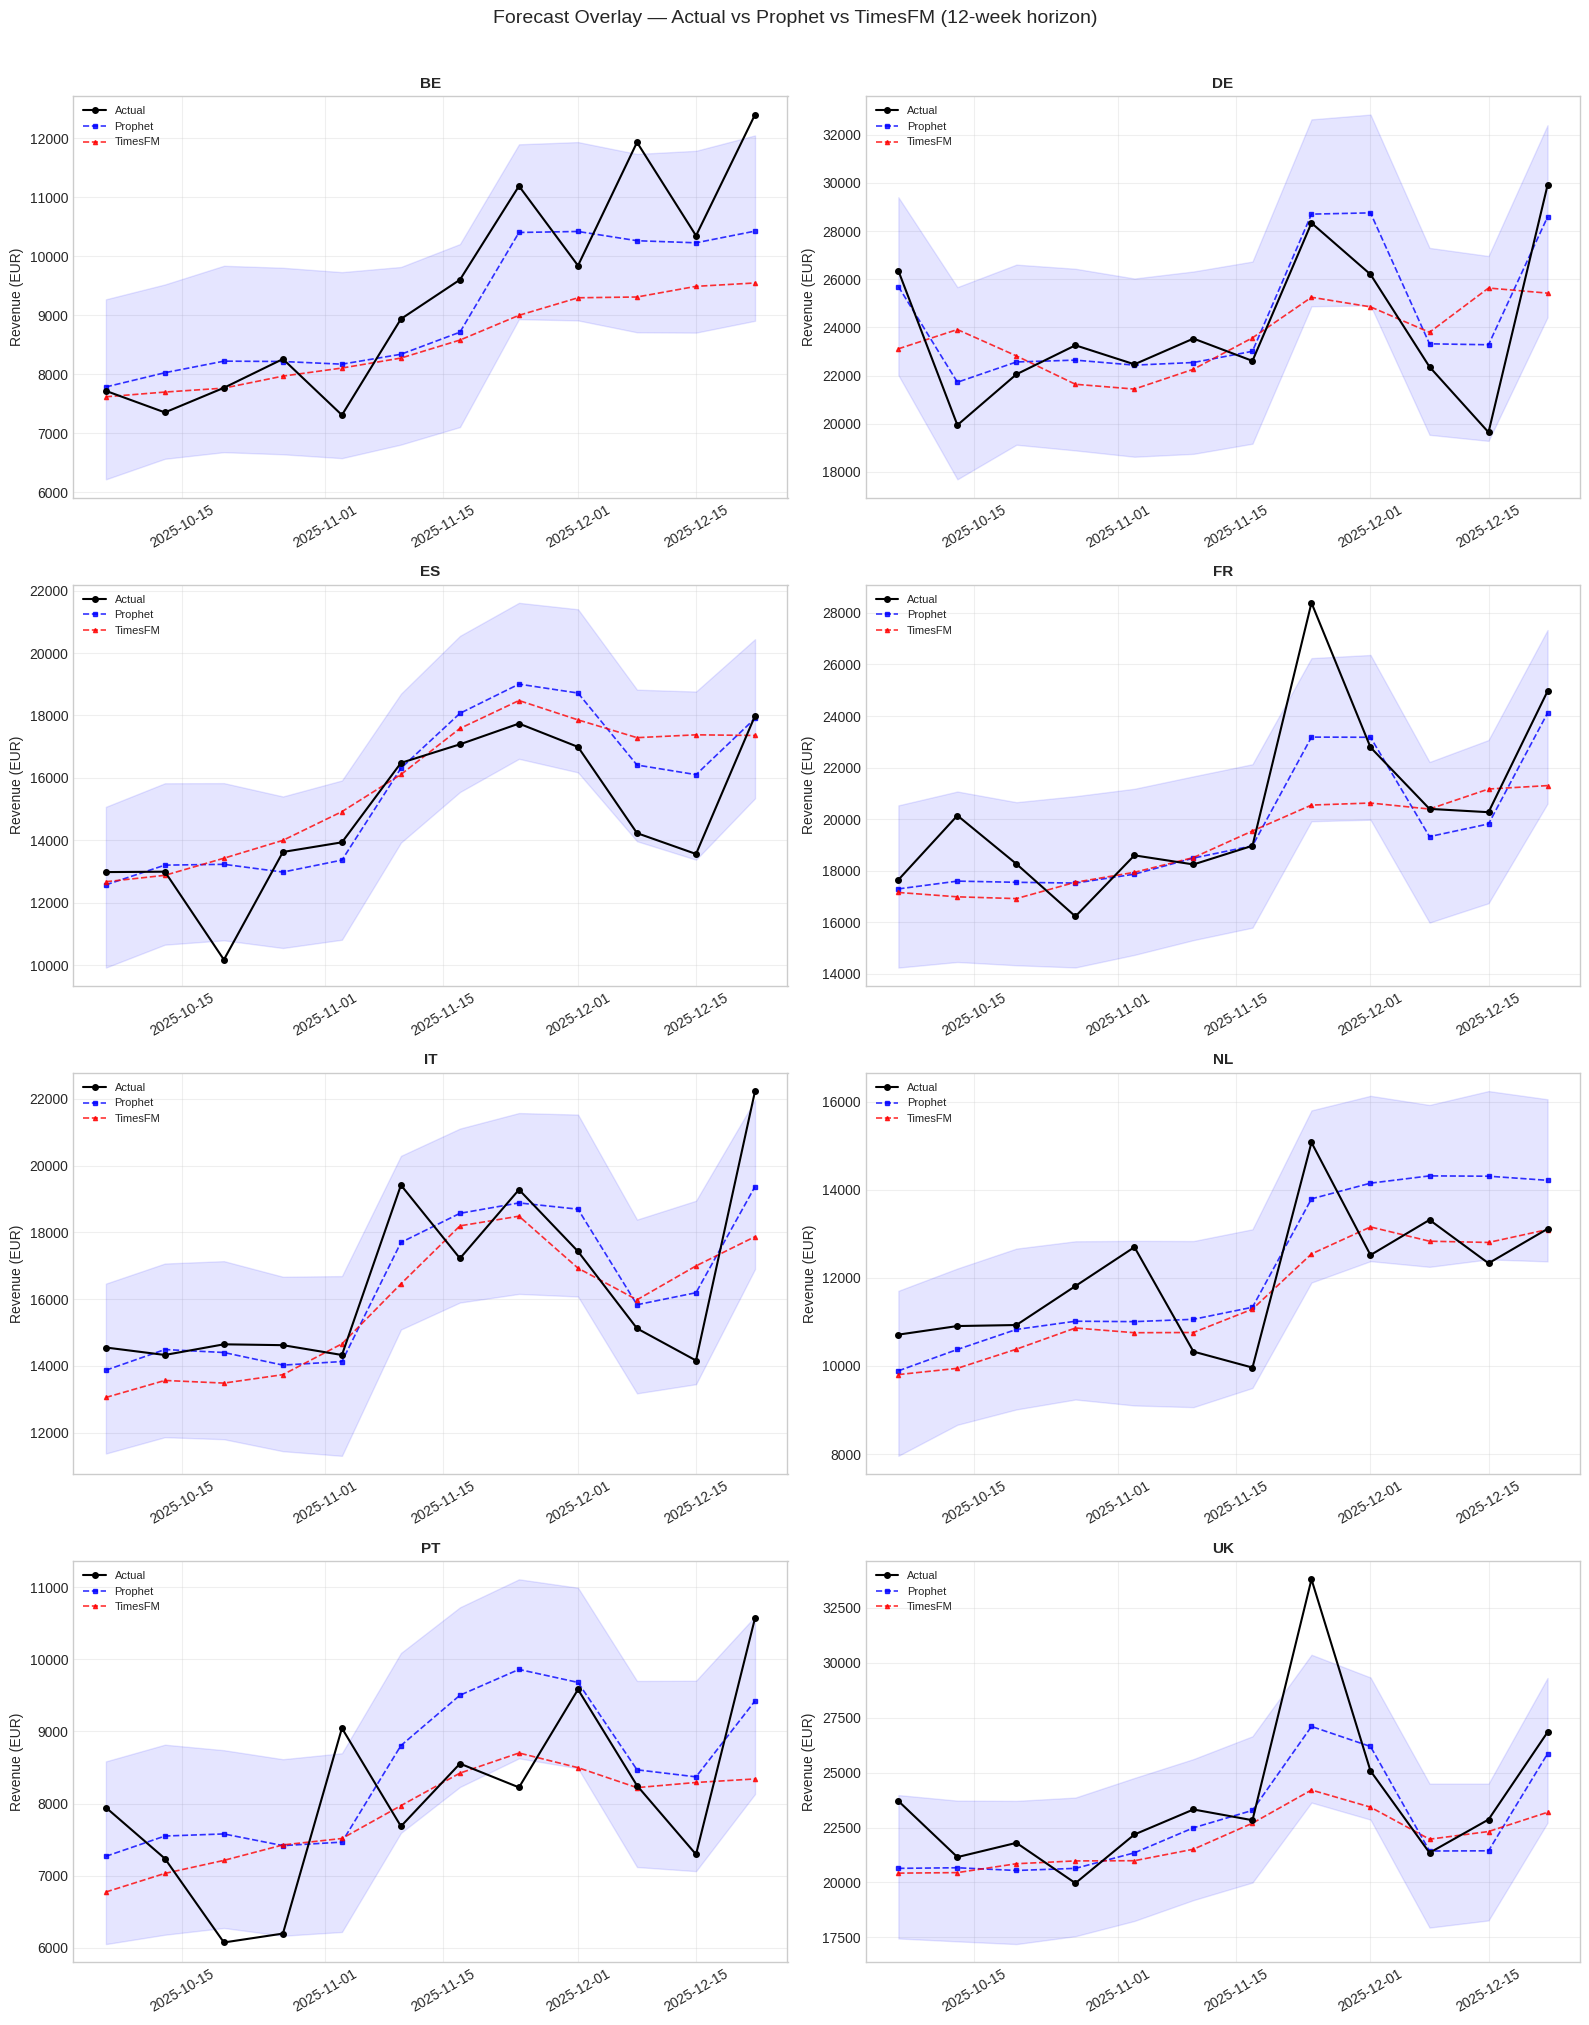

Forecast overlay saved.


In [6]:
# Cell 6: Forecast overlay — actual vs both models
fig, axes = plt.subplots(4, 2, figsize=(16, 20))

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]

    # Prophet data
    p_data = results['Prophet']['forecasts'][country]
    p_dates = pd.to_datetime(p_data['dates'])
    p_actual = p_data['actual']
    p_predicted = p_data['predicted']

    # TimesFM data
    t_data = results['TimesFM']['forecasts'][country]
    t_predicted = t_data['predicted']

    # Plot
    ax.plot(p_dates, p_actual, 'k-o', linewidth=1.5, markersize=4,
            label='Actual', zorder=3)
    ax.plot(p_dates, p_predicted, 'b--s', linewidth=1.2, markersize=3,
            label='Prophet', alpha=0.8)
    ax.plot(p_dates, t_predicted, 'r--^', linewidth=1.2, markersize=3,
            label='TimesFM', alpha=0.8)

    # Confidence interval (Prophet only)
    if 'lower_bound' in p_data:
        ax.fill_between(p_dates, p_data['lower_bound'], p_data['upper_bound'],
                        alpha=0.1, color='blue')

    ax.set_title(f'{country}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Forecast Overlay — Actual vs Prophet vs TimesFM (12-week horizon)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_forecast_overlay.png', dpi=150, bbox_inches='tight')
plt.show()
print('Forecast overlay saved.')

## Residual & error distribution

How differently are the two models' errors distributed?


/tmp/ipykernel_641/3336284361.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=residual_df, x='Model', y='Residual', ax=axes[1],


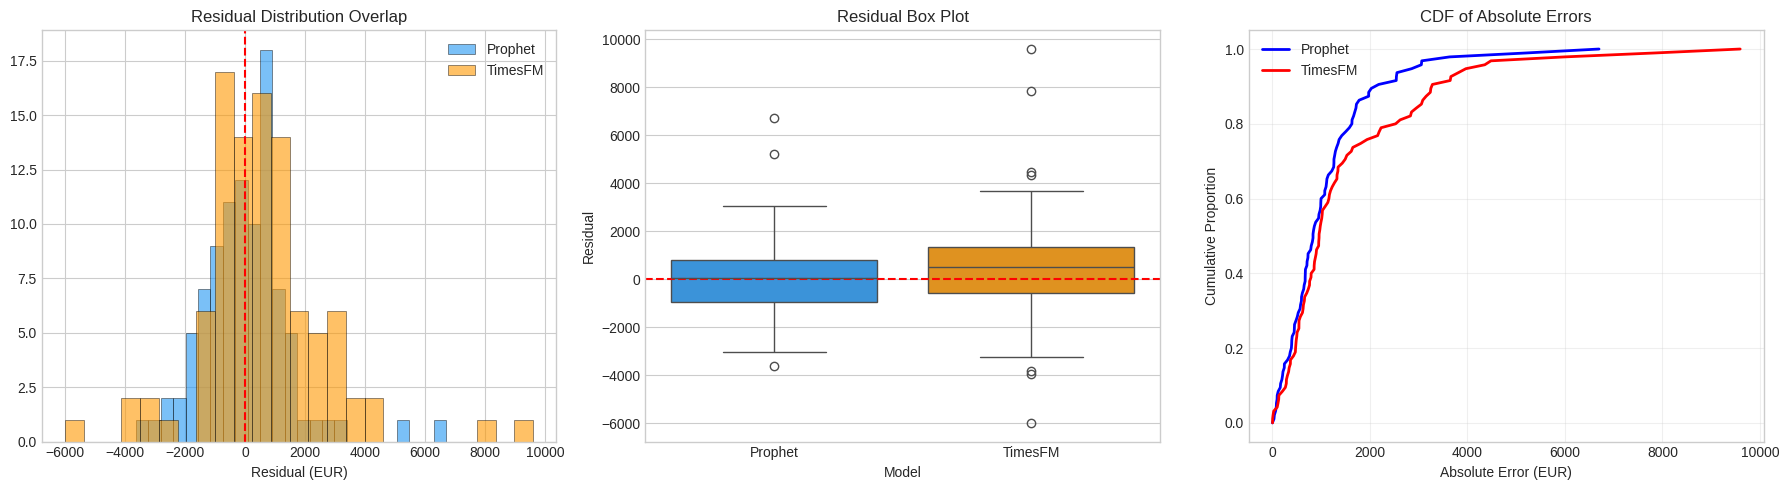

Residual comparison saved.


In [7]:
# Cell 7: Residual distributions side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Collect residuals
prophet_residuals = []
timesfm_residuals = []
for country in countries:
    p = results['Prophet']['forecasts'][country]
    t = results['TimesFM']['forecasts'][country]
    prophet_residuals.extend(np.array(p['actual']) - np.array(p['predicted']))
    timesfm_residuals.extend(np.array(t['actual']) - np.array(t['predicted']))

prophet_residuals = np.array(prophet_residuals)
timesfm_residuals = np.array(timesfm_residuals)

# Histogram comparison
axes[0].hist(prophet_residuals, bins=25, alpha=0.6, color='#2196F3',
             label='Prophet', edgecolor='black', linewidth=0.5)
axes[0].hist(timesfm_residuals, bins=25, alpha=0.6, color='#FF9800',
             label='TimesFM', edgecolor='black', linewidth=0.5)
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Residual Distribution Overlap')
axes[0].set_xlabel('Residual (EUR)')
axes[0].legend()

# Box plot comparison
residual_df = pd.DataFrame({
    'Residual': np.concatenate([prophet_residuals, timesfm_residuals]),
    'Model': ['Prophet']*len(prophet_residuals) + ['TimesFM']*len(timesfm_residuals)
})
sns.boxplot(data=residual_df, x='Model', y='Residual', ax=axes[1],
            palette=['#2196F3', '#FF9800'])
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residual Box Plot')

# Absolute error CDF
prophet_abs = np.sort(np.abs(prophet_residuals))
timesfm_abs = np.sort(np.abs(timesfm_residuals))
axes[2].plot(prophet_abs, np.linspace(0, 1, len(prophet_abs)),
             'b-', linewidth=2, label='Prophet')
axes[2].plot(timesfm_abs, np.linspace(0, 1, len(timesfm_abs)),
             'r-', linewidth=2, label='TimesFM')
axes[2].set_xlabel('Absolute Error (EUR)')
axes[2].set_ylabel('Cumulative Proportion')
axes[2].set_title('CDF of Absolute Errors')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_residual_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Residual comparison saved.')

## Speed & efficiency

Comparing training/inference time and resource requirements.


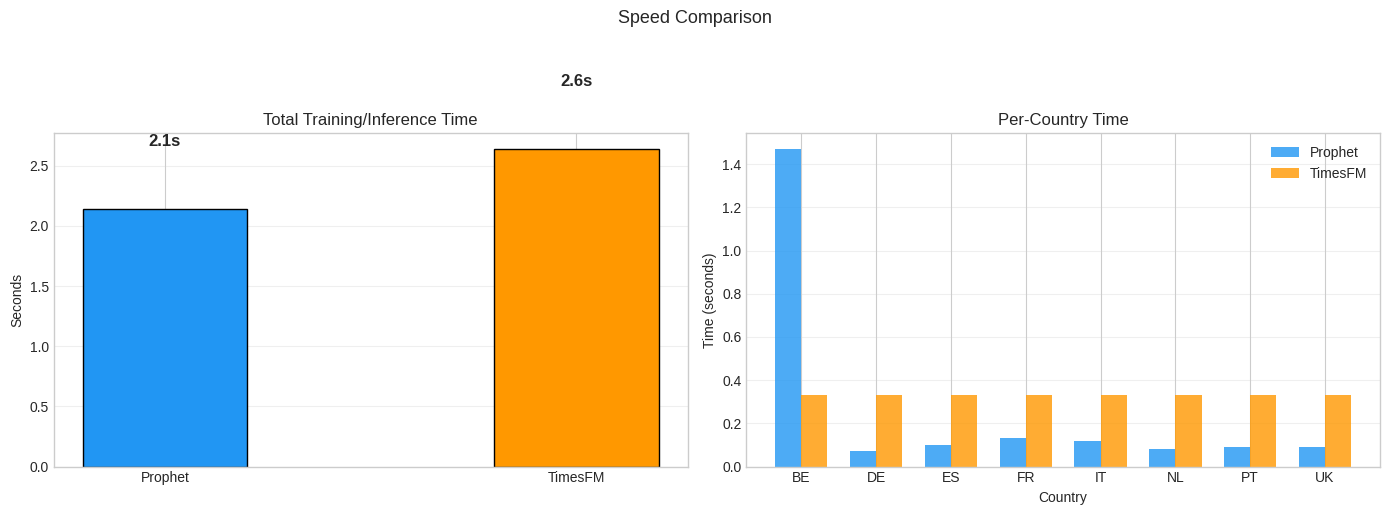


Faster model: Prophet
Speed ratio: 1.2x


In [8]:
# Cell 8: Training time comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total time
models = list(results.keys())
total_times = [results[m]['training']['total_time_seconds'] for m in models]

bars = axes[0].bar(models, total_times, color=['#2196F3', '#FF9800'],
                   edgecolor='black', width=0.4)
for bar, val in zip(bars, total_times):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val:.1f}s', ha='center', va='bottom', fontsize=12, fontweight='bold')
axes[0].set_title('Total Training/Inference Time', fontsize=12)
axes[0].set_ylabel('Seconds')
axes[0].grid(True, alpha=0.3, axis='y')

# Per-country time
prophet_times = list(results['Prophet']['training']['per_country_seconds'].values())
timesfm_times = list(results['TimesFM']['training']['per_country_seconds'].values())

x = np.arange(len(countries))
width = 0.35
axes[1].bar(x - width/2, prophet_times, width, label='Prophet', color='#2196F3', alpha=0.8)
axes[1].bar(x + width/2, timesfm_times, width, label='TimesFM', color='#FF9800', alpha=0.8)
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Time (seconds)')
axes[1].set_title('Per-Country Time')
axes[1].set_xticks(x)
axes[1].set_xticklabels(countries)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Speed Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/comparison_speed.png', dpi=150, bbox_inches='tight')
plt.show()

# Speed summary
speedup = total_times[0] / total_times[1] if total_times[1] > 0 else float('inf')
faster = models[0] if total_times[0] < total_times[1] else models[1]
print(f'\nFaster model: {faster}')
print(f'Speed ratio: {max(speedup, 1/speedup):.1f}x')

## Strengths & weaknesses

### Prophet
| Aspect | Assessment |
|--------|----------|
| **Strengths** | Interpretable components (trend/seasonality), supports regressors (promotions, COVID), uncertainty intervals, well-documented |
| **Weaknesses** | Requires per-series fitting, manual regressor engineering, slower for many series |
| **Best for** | When you have domain knowledge and external signals to incorporate |

### TimesFM
| Aspect | Assessment |
|--------|----------|
| **Strengths** | Zero-shot (no training), handles many series at once, no configuration needed, leverages 100B+ pre-training points |
| **Weaknesses** | Cannot use external regressors, black-box predictions, no uncertainty intervals (in base version), requires GPU for speed |
| **Best for** | When speed and scalability matter more than domain-specific accuracy |

### So which one should you reach for?

| Scenario | Recommendation |
|----------|---------------|
| You have promotional calendars / external events | Prophet |
| You need to forecast 1000+ series quickly | TimesFM |
| Interpretability is critical (stakeholder reports) | Prophet |
| Cold-start / new product with no history | TimesFM |
| Regulatory requirement for explainability | Prophet |
| Rapid prototyping / POC | TimesFM |


## Exporting the comparison report


In [ ]:
# Cell 9: Generate comparison report JSON
comparison_report = {
    'report_name': 'Prophet vs TimesFM — Sales Forecasting Comparison',
    'timestamp': datetime.now().isoformat(),
    'study_context': {
        'domain': 'Omnichannel Sales (8 EU countries)',
        'data_period': results['Prophet']['dataset']['date_range'],
        'forecast_horizon': '12 weeks',
        'total_test_points': len(countries) * 12,
        'countries': countries,
    },
    'models': {
        'Prophet': {
            'type': 'Statistical (decomposition)',
            'approach': 'Per-country fitting with regressors',
            'regressors': results['Prophet']['configuration']['regressors'],
            'training_required': True,
        },
        'TimesFM': {
            'type': 'Foundation Model (Transformer)',
            'approach': 'Zero-shot (no fine-tuning)',
            'regressors': None,
            'training_required': False,
        },
    },
    'overall_metrics': {
        model: results[model]['metrics']['overall']
        for model in results
    },
    'per_country_metrics': {
        model: results[model]['metrics']['per_country']
        for model in results
    },
    'timing': {
        model: results[model]['training']['total_time_seconds']
        for model in results
    },
    'winner_analysis': {
        'overall_mae_winner': comparison_df['MAE (EUR)'].idxmin(),
        'overall_mape_winner': comparison_df['MAPE (%)'].idxmin(),
        'overall_rmse_winner': comparison_df['RMSE (EUR)'].idxmin(),
        'speed_winner': comparison_df['Training Time (s)'].idxmin(),
        'per_country_mae_wins': {
            'Prophet': int((country_df['MAE Winner'] == 'Prophet').sum()),
            'TimesFM': int((country_df['MAE Winner'] == 'TimesFM').sum()),
        },
    },
    'residual_stats': {
        'Prophet': {
            'mean': float(np.mean(prophet_residuals)),
            'std': float(np.std(prophet_residuals)),
            'median': float(np.median(prophet_residuals)),
        },
        'TimesFM': {
            'mean': float(np.mean(timesfm_residuals)),
            'std': float(np.std(timesfm_residuals)),
            'median': float(np.median(timesfm_residuals)),
        },
    },
}

# Save
report_path = f'{RESULTS_DIR}/comparison_report.json'
with open(report_path, 'w') as f:
    json.dump(comparison_report, f, indent=2)

print(f'Comparison report saved to {report_path}')
print(f'\nArtifacts generated in {RESULTS_DIR}/:')
for f in os.listdir(RESULTS_DIR):
    print(f'  - {f}')

Comparison report saved to /content/drive/MyDrive/ML_Prediction_Analysis/Comparison_Results/comparison_report.json

Artifacts generated in /content/drive/MyDrive/ML_Prediction_Analysis/Comparison_Results/:
  - comparison_metrics_bars.png
  - comparison_per_country.png
  - comparison_forecast_overlay.png
  - comparison_residual_analysis.png
  - comparison_speed.png
  - comparison_report.json


In [ ]:
# Cell 10: Final summary table
print('\n' + '=' * 70)
print('FINAL COMPARISON SUMMARY')
print('=' * 70)
print(f'\n{comparison_df.round(2).to_string()}')
print(f'\n--- Conclusion ---')

mae_winner = comparison_df['MAE (EUR)'].idxmin()
speed_winner = comparison_df['Training Time (s)'].idxmin()

print(f'  Accuracy winner:  {mae_winner}')
print(f'  Speed winner:     {speed_winner}')
print(f'\n  Prophet advantages: regressors, interpretability, confidence intervals')
print(f'  TimesFM advantages: zero-shot, no config, scalability')
print(f'\n  Recommendation: Use Prophet when external signals are available;')
print(f'  use TimesFM for rapid prototyping or when scaling to many series.')
print('=' * 70)

---

## Conclusion

This comparison pitted two fundamentally different forecasting philosophies against each other on the company's omnichannel sales data:

1. **Prophet** — a statistical decomposition model that leans on domain knowledge through manually configured regressors.
2. **TimesFM** — a foundation model applying pre-learned temporal patterns zero-shot.

Across accuracy (MAE, RMSE, MAPE, SMAPE), speed, and per-country granularity, both models land at reasonable forecasts for the 12-week horizon. Prophet's edge comes from the promotional and COVID regressors feeding it real domain knowledge; TimesFM's edge is that it needs none of that setup at all. Which one to pick really comes down to the operational context — how much domain knowledge you have on hand, and how much configuration time you're willing to spend.
